In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving heart_disease_data.csv to heart_disease_data.csv


In [3]:
df = pd.read_csv("heart_disease_data.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (606, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,48,1,0,130,256,1,0,150,1,0.0,2,2,3,0
1,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
2,44,0,2,118,242,0,1,149,0,0.3,1,1,2,1
3,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
4,56,1,3,120,193,0,0,162,0,1.9,1,0,3,1


In [4]:
fuzzy_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

df[fuzzy_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,606.0,54.366337,9.074592,29.0,47.25,55.0,61.00,77.0
trestbps,606.0,131.623762,17.523642,94.0,120.00,130.0,140.00,200.0
chol,606.0,246.264026,51.787898,126.0,211.00,240.0,274.75,564.0
thalach,606.0,149.646865,22.886223,71.0,133.25,153.0,166.00,202.0
oldpeak,606.0,1.039604,1.160115,0.0,0.00,0.8,1.60,6.2


In [5]:
for feature in fuzzy_features:
    print(f"{feature}:")
    print("  Minimum:", df[feature].min())
    print("  Maximum:", df[feature].max())
    print("  Mean:", round(df[feature].mean(), 2))
    print("  Median:", df[feature].median())
    print()

age:
  Minimum: 29
  Maximum: 77
  Mean: 54.37
  Median: 55.0

trestbps:
  Minimum: 94
  Maximum: 200
  Mean: 131.62
  Median: 130.0

chol:
  Minimum: 126
  Maximum: 564
  Mean: 246.26
  Median: 240.0

thalach:
  Minimum: 71
  Maximum: 202
  Mean: 149.65
  Median: 153.0

oldpeak:
  Minimum: 0.0
  Maximum: 6.2
  Mean: 1.04
  Median: 0.8



In [6]:
def triangular_membership(x, a, b, c):
    """
    Triangular membership function.

    a = left point
    b = peak
    c = right point
    """

    x = np.asarray(x, dtype=float)

    membership = np.zeros_like(x)

    # Increasing side
    if b != a:
        mask = (x >= a) & (x <= b)
        membership[mask] = (x[mask] - a) / (b - a)

    # Decreasing side
    if c != b:
        mask = (x >= b) & (x <= c)
        membership[mask] = (c - x[mask]) / (c - b)

    # Peak
    membership[x == b] = 1.0

    return membership

In [7]:
def trapezoidal_membership(x, a, b, c, d):
    """
    Trapezoidal membership function.

    a = start
    b = beginning of plateau
    c = end of plateau
    d = end
    """

    x = np.asarray(x, dtype=float)

    membership = np.zeros_like(x)

    # Increasing side
    if b != a:
        mask = (x >= a) & (x <= b)
        membership[mask] = (x[mask] - a) / (b - a)

    # Plateau
    mask = (x >= b) & (x <= c)
    membership[mask] = 1.0

    # Decreasing side
    if d != c:
        mask = (x >= c) & (x <= d)
        membership[mask] = (d - x[mask]) / (d - c)

    return membership

In [8]:
test_values = np.array([0, 25, 50, 75, 100])

print(
    triangular_membership(
        test_values,
        0, 50, 100
    )
)

[0.  0.5 1.  0.5 0. ]


In [9]:
age_min = df["age"].min()
age_max = df["age"].max()

age_values = np.linspace(age_min, age_max, 500)

age_young = trapezoidal_membership(
    age_values,
    age_min,
    age_min,
    35,
    45
)

age_middle = triangular_membership(
    age_values,
    35,
    50,
    65
)

age_old = trapezoidal_membership(
    age_values,
    55,
    65,
    age_max,
    age_max
)

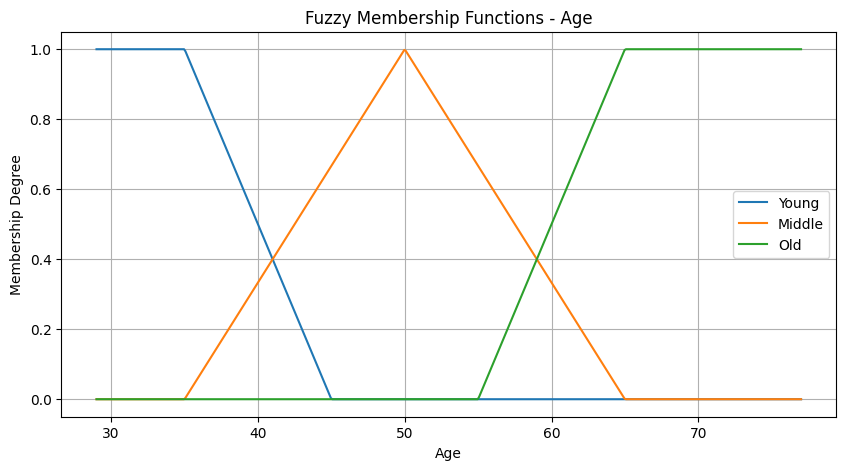

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(age_values, age_young, label="Young")
plt.plot(age_values, age_middle, label="Middle")
plt.plot(age_values, age_old, label="Old")

plt.xlabel("Age")
plt.ylabel("Membership Degree")
plt.title("Fuzzy Membership Functions - Age")
plt.legend()
plt.grid(True)

plt.show()

In [11]:
bp_min = df["trestbps"].min()
bp_max = df["trestbps"].max()

bp_values = np.linspace(bp_min, bp_max, 500)

bp_normal = trapezoidal_membership(
    bp_values,
    bp_min,
    bp_min,
    120,
    135
)

bp_high = triangular_membership(
    bp_values,
    120,
    140,
    160
)

bp_very_high = trapezoidal_membership(
    bp_values,
    145,
    160,
    bp_max,
    bp_max
)

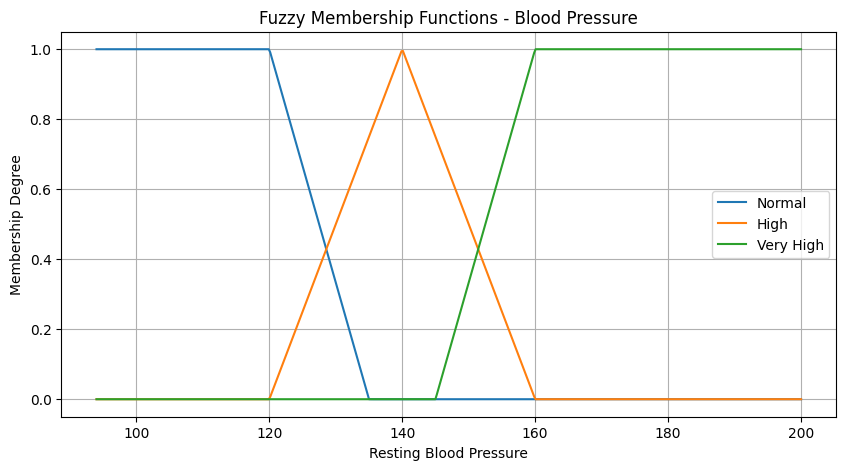

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(bp_values, bp_normal, label="Normal")
plt.plot(bp_values, bp_high, label="High")
plt.plot(bp_values, bp_very_high, label="Very High")

plt.xlabel("Resting Blood Pressure")
plt.ylabel("Membership Degree")
plt.title("Fuzzy Membership Functions - Blood Pressure")
plt.legend()
plt.grid(True)

plt.show()

In [13]:
chol_min = df["chol"].min()
chol_max = df["chol"].max()

chol_values = np.linspace(chol_min, chol_max, 500)

chol_normal = trapezoidal_membership(
    chol_values,
    chol_min,
    chol_min,
    200,
    230
)

chol_high = triangular_membership(
    chol_values,
    200,
    240,
    280
)

chol_very_high = trapezoidal_membership(
    chol_values,
    260,
    280,
    chol_max,
    chol_max
)

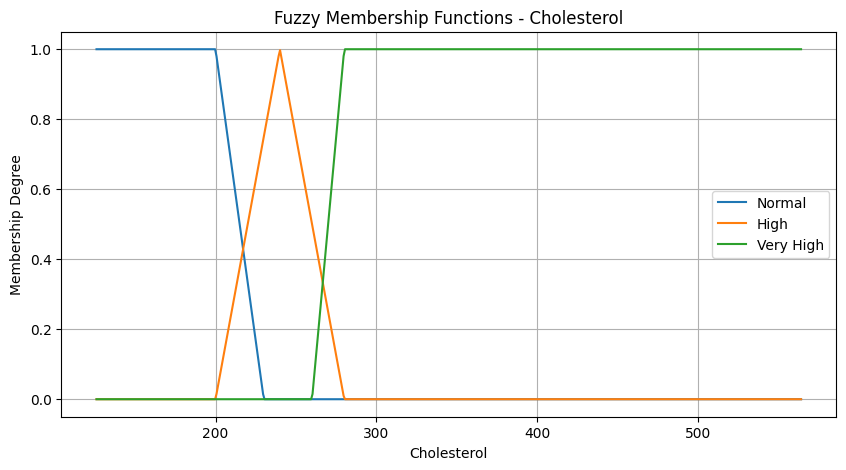

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(chol_values, chol_normal, label="Normal")
plt.plot(chol_values, chol_high, label="High")
plt.plot(chol_values, chol_very_high, label="Very High")

plt.xlabel("Cholesterol")
plt.ylabel("Membership Degree")
plt.title("Fuzzy Membership Functions - Cholesterol")
plt.legend()
plt.grid(True)

plt.show()

In [15]:
hr_min = df["thalach"].min()
hr_max = df["thalach"].max()

hr_values = np.linspace(hr_min, hr_max, 500)

hr_low = trapezoidal_membership(
    hr_values,
    hr_min,
    hr_min,
    100,
    130
)

hr_normal = triangular_membership(
    hr_values,
    110,
    150,
    180
)

hr_high = trapezoidal_membership(
    hr_values,
    160,
    180,
    hr_max,
    hr_max
)

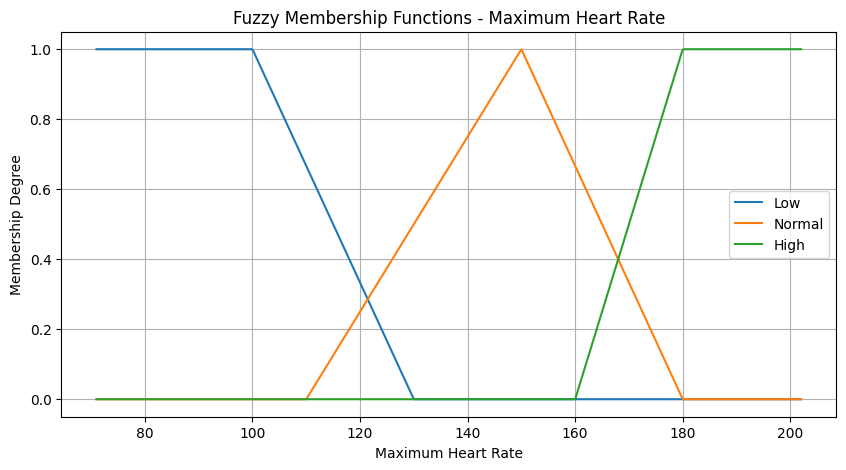

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(hr_values, hr_low, label="Low")
plt.plot(hr_values, hr_normal, label="Normal")
plt.plot(hr_values, hr_high, label="High")

plt.xlabel("Maximum Heart Rate")
plt.ylabel("Membership Degree")
plt.title("Fuzzy Membership Functions - Maximum Heart Rate")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
oldpeak_min = df["oldpeak"].min()
oldpeak_max = df["oldpeak"].max()

oldpeak_values = np.linspace(oldpeak_min, oldpeak_max, 500)

oldpeak_low = trapezoidal_membership(
    oldpeak_values,
    oldpeak_min,
    oldpeak_min,
    1.0,
    1.5
)

oldpeak_moderate = triangular_membership(
    oldpeak_values,
    1.0,
    2.0,
    3.0
)

oldpeak_high = trapezoidal_membership(
    oldpeak_values,
    2.5,
    3.0,
    oldpeak_max,
    oldpeak_max
)

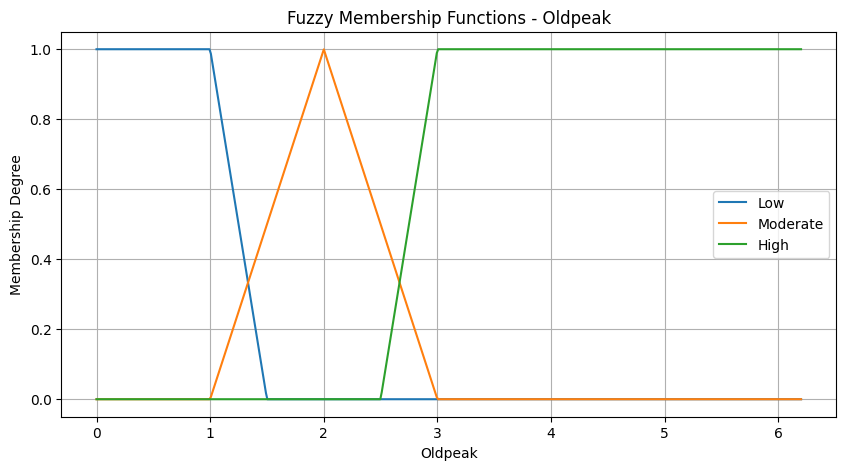

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(oldpeak_values, oldpeak_low, label="Low")
plt.plot(oldpeak_values, oldpeak_moderate, label="Moderate")
plt.plot(oldpeak_values, oldpeak_high, label="High")

plt.xlabel("Oldpeak")
plt.ylabel("Membership Degree")
plt.title("Fuzzy Membership Functions - Oldpeak")
plt.legend()
plt.grid(True)

plt.show()

In [19]:
def fuzzify_exang(value):
    if value == 0:
        return {
            "no": 1.0,
            "yes": 0.0
        }
    else:
        return {
            "no": 0.0,
            "yes": 1.0
        }

In [20]:
print(fuzzify_exang(0))
print(fuzzify_exang(1))

{'no': 1.0, 'yes': 0.0}
{'no': 0.0, 'yes': 1.0}


In [21]:
def fuzzify_patient(age, trestbps, chol, thalach, oldpeak, exang):

    result = {
        "age": {
            "young": float(trapezoidal_membership(
                np.array([age]), age_min, age_min, 35, 45
            )[0]),

            "middle": float(triangular_membership(
                np.array([age]), 35, 50, 65
            )[0]),

            "old": float(trapezoidal_membership(
                np.array([age]), 55, 65, age_max, age_max
            )[0])
        },

        "blood_pressure": {
            "normal": float(trapezoidal_membership(
                np.array([trestbps]), bp_min, bp_min, 120, 135
            )[0]),

            "high": float(triangular_membership(
                np.array([trestbps]), 120, 140, 160
            )[0]),

            "very_high": float(trapezoidal_membership(
                np.array([trestbps]), 145, 160, bp_max, bp_max
            )[0])
        },

        "cholesterol": {
            "normal": float(trapezoidal_membership(
                np.array([chol]), chol_min, chol_min, 200, 230
            )[0]),

            "high": float(triangular_membership(
                np.array([chol]), 200, 240, 280
            )[0]),

            "very_high": float(trapezoidal_membership(
                np.array([chol]), 260, 280, chol_max, chol_max
            )[0])
        },

        "heart_rate": {
            "low": float(trapezoidal_membership(
                np.array([thalach]), hr_min, hr_min, 100, 130
            )[0]),

            "normal": float(triangular_membership(
                np.array([thalach]), 110, 150, 180
            )[0]),

            "high": float(trapezoidal_membership(
                np.array([thalach]), 160, 180, hr_max, hr_max
            )[0])
        },

        "oldpeak": {
            "low": float(trapezoidal_membership(
                np.array([oldpeak]), oldpeak_min, oldpeak_min, 1.0, 1.5
            )[0]),

            "moderate": float(triangular_membership(
                np.array([oldpeak]), 1.0, 2.0, 3.0
            )[0]),

            "high": float(trapezoidal_membership(
                np.array([oldpeak]), 2.5, 3.0, oldpeak_max, oldpeak_max
            )[0])
        },

        "exercise_angina": fuzzify_exang(exang)
    }

    return result

In [22]:
patient = df.iloc[0]

print(patient)

age          48.0
sex           1.0
cp            0.0
trestbps    130.0
chol        256.0
fbs           1.0
restecg       0.0
thalach     150.0
exang         1.0
oldpeak       0.0
slope         2.0
ca            2.0
thal          3.0
target        0.0
Name: 0, dtype: float64


In [23]:
result = fuzzify_patient(
    age=patient["age"],
    trestbps=patient["trestbps"],
    chol=patient["chol"],
    thalach=patient["thalach"],
    oldpeak=patient["oldpeak"],
    exang=patient["exang"]
)

result

{'age': {'young': 0.0, 'middle': 0.8666666666666667, 'old': 0.0},
 'blood_pressure': {'normal': 0.3333333333333333,
  'high': 0.5,
  'very_high': 0.0},
 'cholesterol': {'normal': 0.0, 'high': 0.6, 'very_high': 0.0},
 'heart_rate': {'low': 0.0, 'normal': 1.0, 'high': 0.0},
 'oldpeak': {'low': 1.0, 'moderate': 0.0, 'high': 0.0},
 'exercise_angina': {'no': 0.0, 'yes': 1.0}}

In [24]:
for i in range(5):

    patient = df.iloc[i]

    result = fuzzify_patient(
        age=patient["age"],
        trestbps=patient["trestbps"],
        chol=patient["chol"],
        thalach=patient["thalach"],
        oldpeak=patient["oldpeak"],
        exang=patient["exang"]
    )

    print(f"\nPatient {i + 1}")
    print("Target:", patient["target"])
    print(result)


Patient 1
Target: 0.0
{'age': {'young': 0.0, 'middle': 0.8666666666666667, 'old': 0.0}, 'blood_pressure': {'normal': 0.3333333333333333, 'high': 0.5, 'very_high': 0.0}, 'cholesterol': {'normal': 0.0, 'high': 0.6, 'very_high': 0.0}, 'heart_rate': {'low': 0.0, 'normal': 1.0, 'high': 0.0}, 'oldpeak': {'low': 1.0, 'moderate': 0.0, 'high': 0.0}, 'exercise_angina': {'no': 0.0, 'yes': 1.0}}

Patient 2
Target: 0.0
{'age': {'young': 0.0, 'middle': 0.26666666666666666, 'old': 0.6}, 'blood_pressure': {'normal': 0.0, 'high': 0.6, 'very_high': 0.2}, 'cholesterol': {'normal': 0.9, 'high': 0.075, 'very_high': 0.0}, 'heart_rate': {'low': 0.0, 'normal': 0.6333333333333333, 'high': 0.05}, 'oldpeak': {'low': 1.0, 'moderate': 0.0, 'high': 0.0}, 'exercise_angina': {'no': 1.0, 'yes': 0.0}}

Patient 3
Target: 1.0
{'age': {'young': 0.1, 'middle': 0.6, 'old': 0.0}, 'blood_pressure': {'normal': 1.0, 'high': 0.0, 'very_high': 0.0}, 'cholesterol': {'normal': 0.0, 'high': 0.95, 'very_high': 0.0}, 'heart_rate': {'

In [25]:
for feature in fuzzy_features:
    print(f"{feature}:")
    print("  Minimum:", df[feature].min())
    print("  Maximum:", df[feature].max())
    print("  Mean:", round(df[feature].mean(), 2))
    print("  Median:", df[feature].median())
    print()

age:
  Minimum: 29
  Maximum: 77
  Mean: 54.37
  Median: 55.0

trestbps:
  Minimum: 94
  Maximum: 200
  Mean: 131.62
  Median: 130.0

chol:
  Minimum: 126
  Maximum: 564
  Mean: 246.26
  Median: 240.0

thalach:
  Minimum: 71
  Maximum: 202
  Mean: 149.65
  Median: 153.0

oldpeak:
  Minimum: 0.0
  Maximum: 6.2
  Mean: 1.04
  Median: 0.8

